# Task 3: Compare degree-0/degree-1 SH and opacity pruning

Open this notebook in VS Code and connect it to a **Google Colab GPU runtime**. Run the cells from top to bottom. Colab clones or fast-forwards the repository, so **commit and push the code you want to test to the repository's default branch first**. The notebook compares SH degrees 0 and 1 across all five cameras, then sweeps opacity thresholds. It saves rendered images, plots, and CSV summaries under `report/images/task3_sh_comparison/`.

In [4]:
import os
import pathlib
import subprocess

repo_url = 'https://github.com/jon-of-us/gaussian-splatting-homwork.git'
assignment_root = pathlib.Path('/content/hw1_2026_student')

if (assignment_root / '.git').is_dir():
    subprocess.run(
        ['git', '-C', str(assignment_root), 'pull', '--ff-only'],
        check=True,
    )
elif assignment_root.exists():
    raise FileExistsError(
        f'{assignment_root} exists but is not a Git checkout. '
        'Rename it in the Colab runtime, then rerun this cell.'
    )
else:
    subprocess.run(
        ['git', 'clone', '--depth', '1', repo_url, str(assignment_root)],
        check=True,
    )

required_files = [
    assignment_root / 'gaussian_model.py',
    assignment_root / 'submodules/diff-gaussian-rasterization/cuda_rasterizer/forward.cu',
    assignment_root / 'scripts/setup_environment.sh',
    assignment_root / 'assets/gs_cloud.ply',
]
missing_files = [str(path) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f'Repository checkout is missing required files: {missing_files}')

os.chdir(assignment_root)
print(f'Assignment directory: {pathlib.Path.cwd()}')

Assignment directory: /content/hw1_2026_student


In [5]:
import pathlib
import subprocess
import sys
import torch
import torchvision
import torch.utils.cpp_extension

if not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Connect to a Colab GPU runtime, then rerun.')
if torch.utils.cpp_extension.CUDA_HOME is None:
    raise RuntimeError('CUDA Toolkit was not found. Use a Colab GPU runtime with nvcc installed.')

subprocess.run(['nvidia-smi'], check=True)
nvcc = pathlib.Path(torch.utils.cpp_extension.CUDA_HOME) / 'bin' / 'nvcc'
if not nvcc.is_file():
    raise FileNotFoundError(f'CUDA compiler was not found: {nvcc}')
subprocess.run([str(nvcc), '--version'], check=True)

print(f'Python: {sys.version.split()[0]}')
print(f'PyTorch: {torch.__version__}')
print(f'torchvision: {torchvision.__version__}')
print(f'PyTorch CUDA: {torch.version.cuda}')
print(f'GPU: {torch.cuda.get_device_name(0)}')

Python: 3.13.16
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
PyTorch CUDA: 13.0
GPU: Tesla T4


## Build the CUDA extension

This uses the repository setup helper and the notebook kernel's Python. Run it once per fresh Colab runtime.

In [6]:
import os
import sys
import subprocess

build_env = os.environ.copy()
build_env['HW1_PYTHON'] = sys.executable
build_env['MAX_JOBS'] = '2'
subprocess.run(
    ['bash', 'scripts/setup_environment.sh'],
    cwd=assignment_root,
    env=build_env,
    check=True,
)

CompletedProcess(args=['bash', 'scripts/setup_environment.sh'], returncode=0)

## Render both SH degrees

Each timed run includes model loading, rendering all five cameras, and writing the PNGs. Three alternating-order trials reduce the effect of run order; the median is used in the timing plot. The final images for each degree are copied to separate folders so the next run cannot overwrite them.

In [7]:
import pathlib
import shutil
import subprocess
import sys
import time

comparison_dir = assignment_root / 'report/images/task3_sh_comparison'
comparison_dir.mkdir(parents=True, exist_ok=True)
degree_dirs = {
    degree: comparison_dir / f'sh_degree_{degree}'
    for degree in (0, 1)
}
for output_dir in degree_dirs.values():
    output_dir.mkdir(parents=True, exist_ok=True)

repeat_count = 3
run_times = {0: [], 1: []}
render_dir = assignment_root / 'renders'

for trial in range(repeat_count):
    degree_order = (0, 1) if trial % 2 == 0 else (1, 0)
    for degree in degree_order:
        started = time.perf_counter()
        subprocess.run(
            [sys.executable, 'render.py', '--sh_degree', str(degree)],
            cwd=assignment_root,
            check=True,
        )
        elapsed = time.perf_counter() - started
        run_times[degree].append(elapsed)
        print(f'Trial {trial + 1}, SH degree {degree}: {elapsed:.2f} seconds')

        if trial == repeat_count - 1:
            for camera_index in range(5):
                source = render_dir / f'{camera_index:05d}.png'
                if not source.is_file() or source.stat().st_size == 0:
                    raise FileNotFoundError(f'Missing or empty render: {source}')
                shutil.copy2(source, degree_dirs[degree] / source.name)

print('Saved final five-view render sets under:', comparison_dir)

Trial 1, SH degree 0: 5.92 seconds
Trial 1, SH degree 1: 6.46 seconds
Trial 2, SH degree 1: 5.76 seconds
Trial 2, SH degree 0: 6.62 seconds
Trial 3, SH degree 0: 5.85 seconds
Trial 3, SH degree 1: 6.31 seconds
Saved final five-view render sets under: /content/hw1_2026_student/report/images/task3_sh_comparison


## Compare image quality and rendering time

The contact sheet compares each output with its supplied ground-truth view. Per-view MAE and PSNR are simple image-error summaries, not substitutes for visual inspection. All generated plots are saved in the comparison subfolder.

Median all-view times (seconds): {0: 5.921554283999967, 1: 6.314305862999845}
Saved plots and CSV summaries under: /content/hw1_2026_student/report/images/task3_sh_comparison


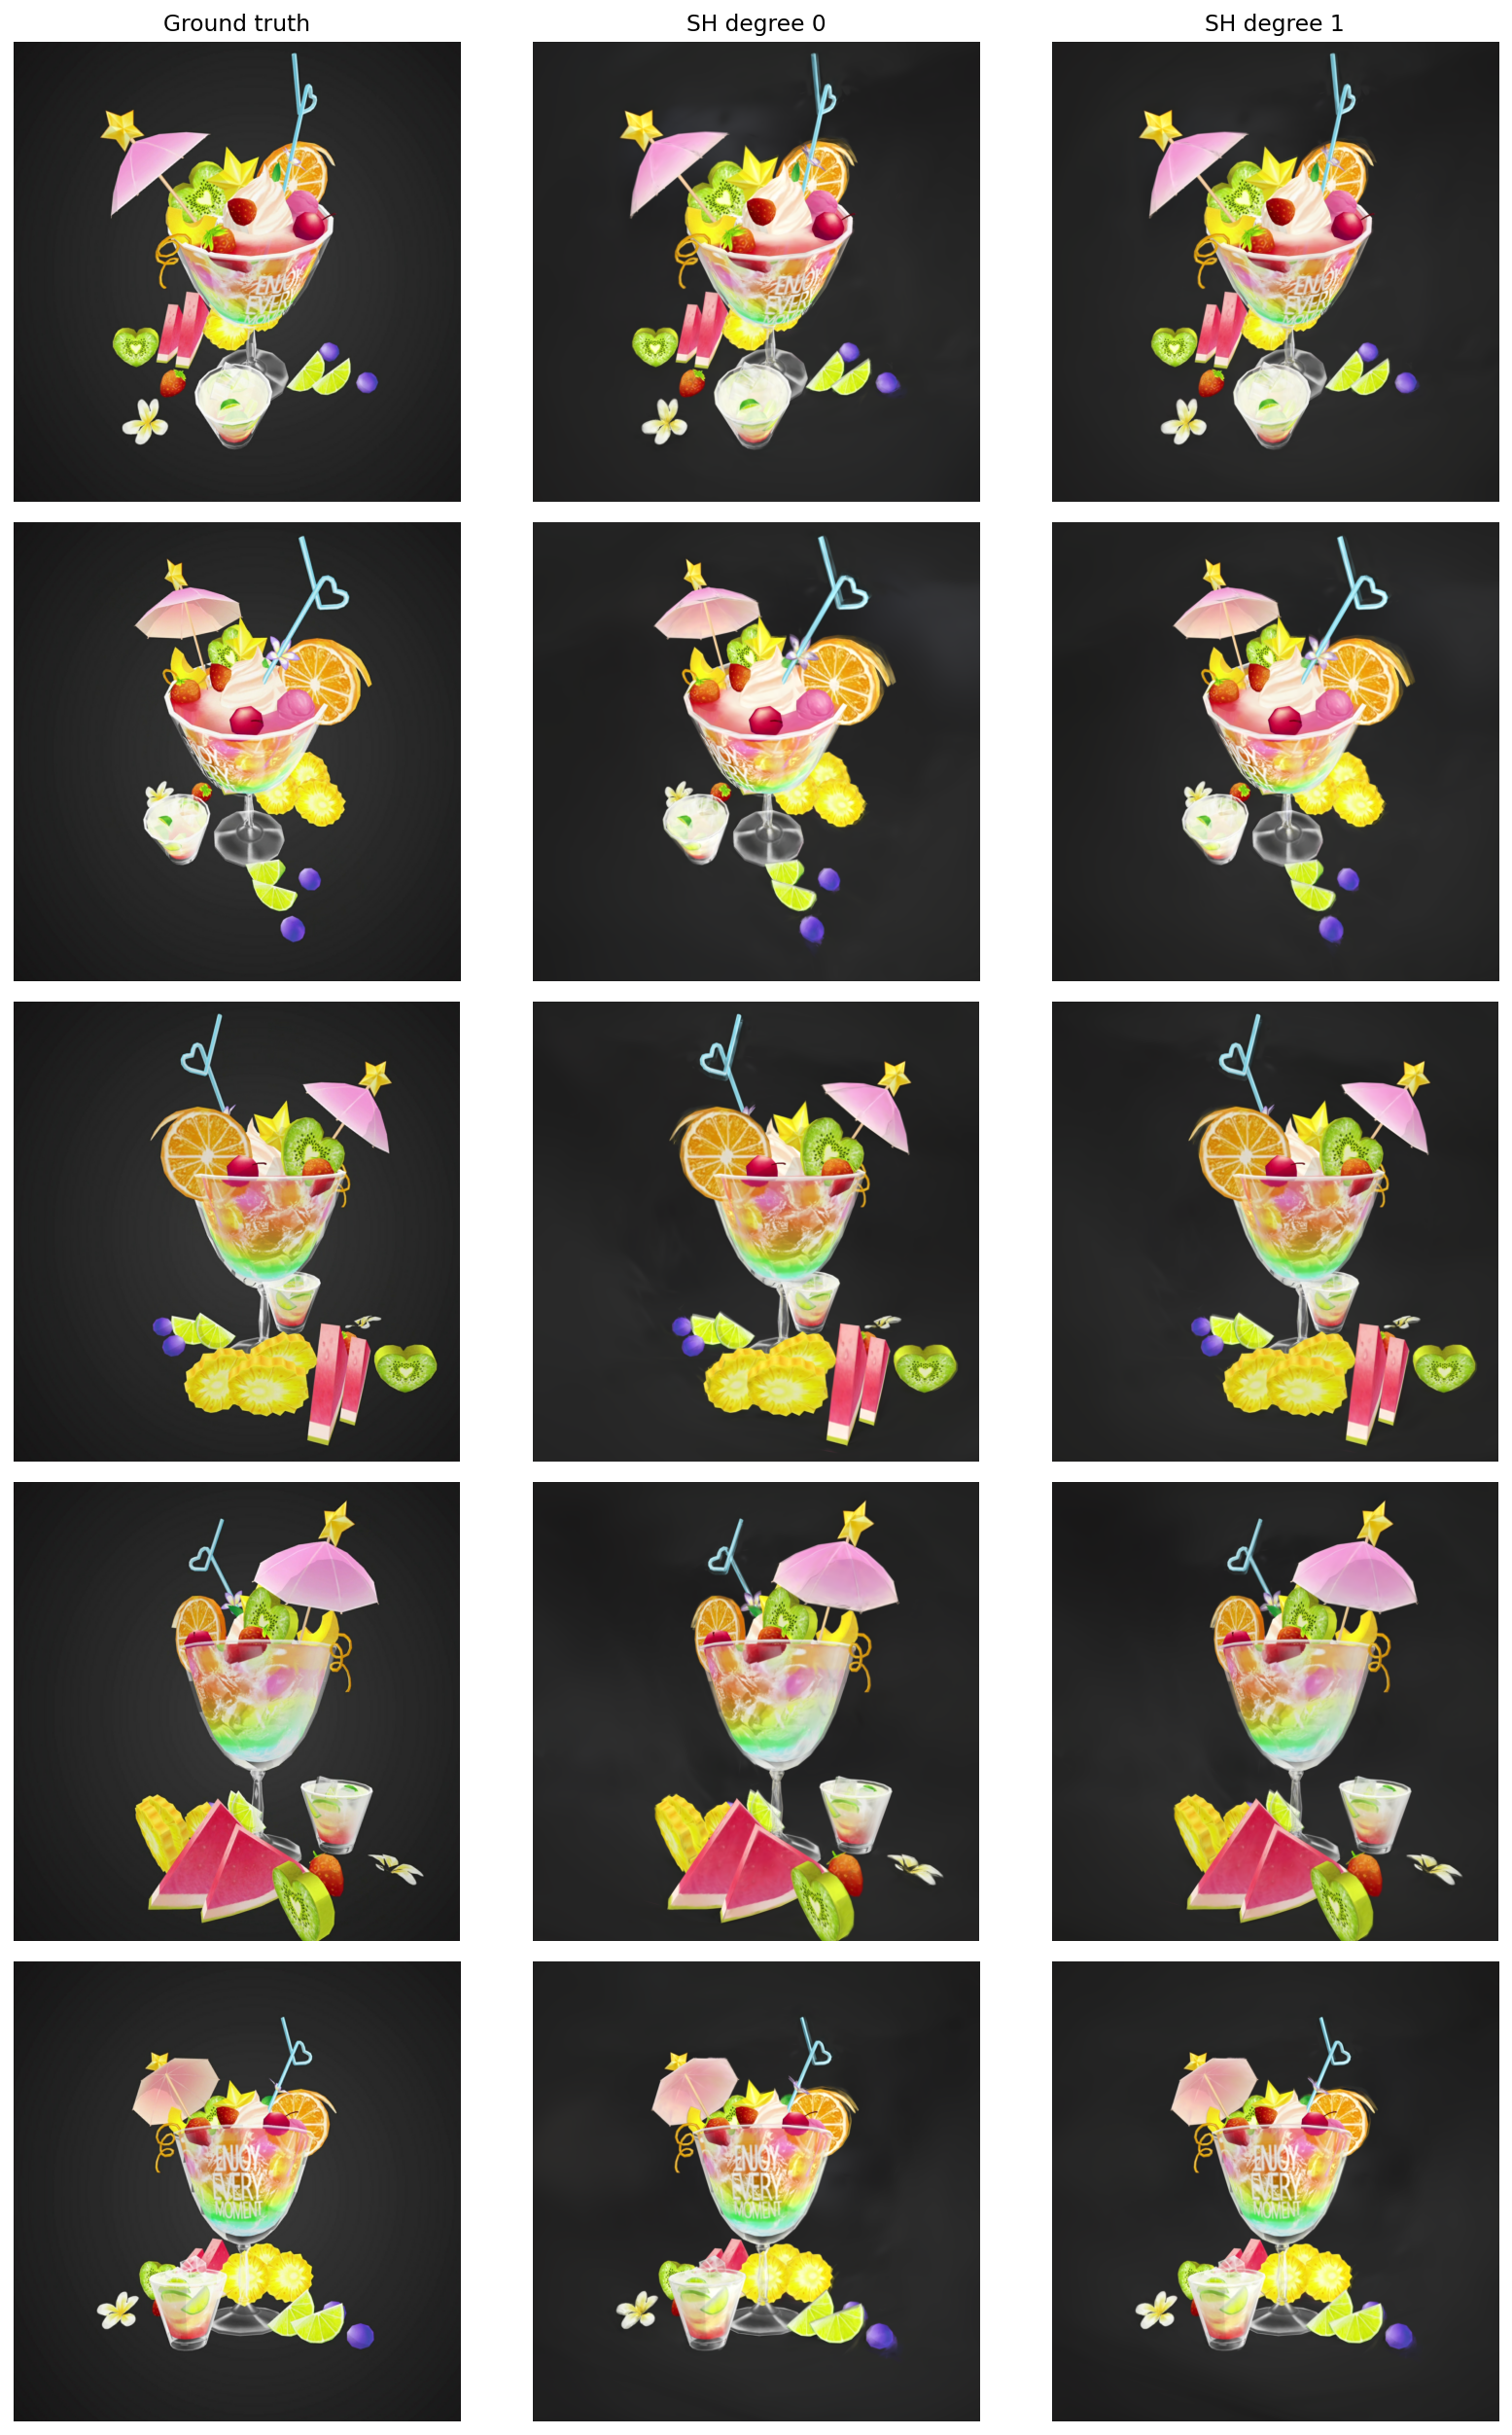

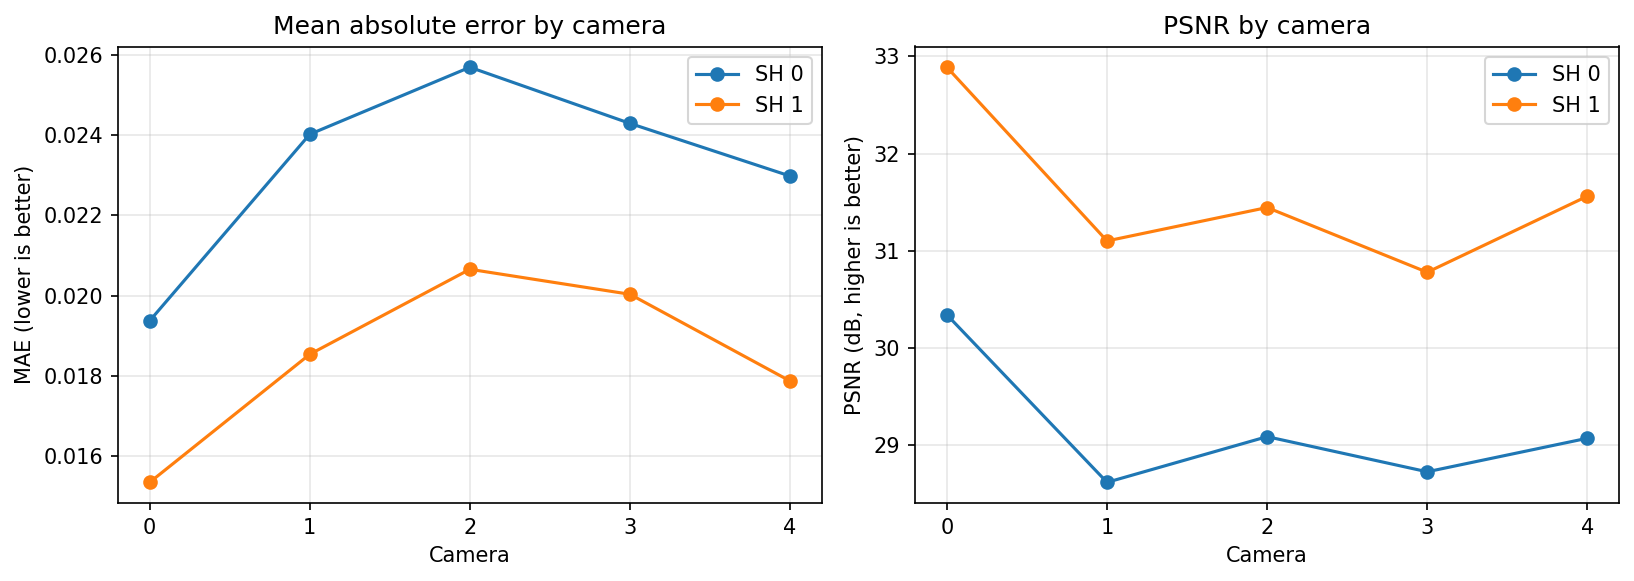

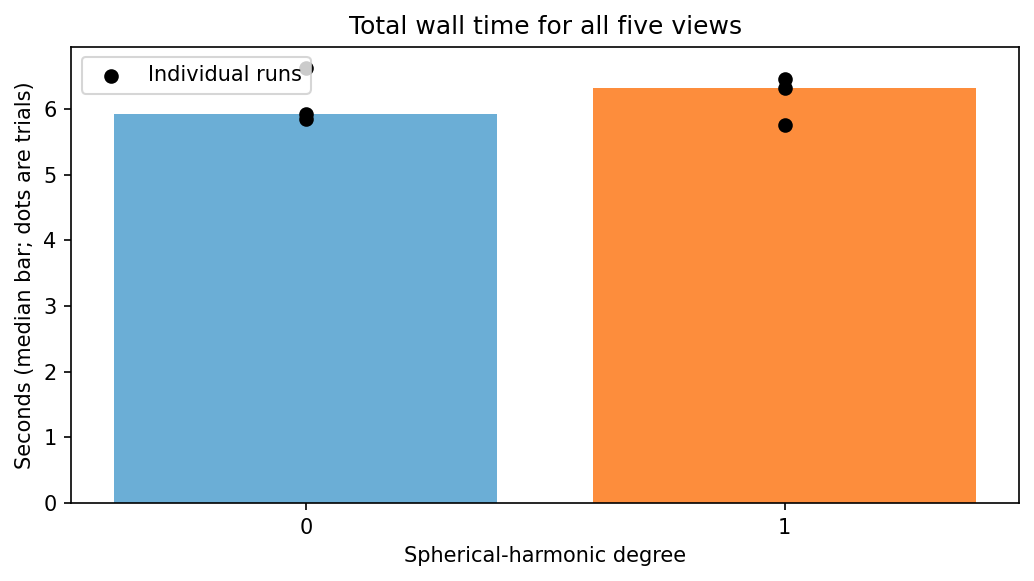

In [8]:
import csv
import math
import statistics
import numpy as np
import PIL.Image
import matplotlib.pyplot as plt
import IPython.display

metrics = {degree: {'mae': [], 'psnr': []} for degree in (0, 1)}
metric_rows = []
reference_images = []
rendered_images = {degree: [] for degree in (0, 1)}

for camera_index in range(5):
    reference_path = assignment_root / f'assets/gt/{camera_index}.png'
    if not reference_path.is_file():
        raise FileNotFoundError(f'Missing ground-truth image: {reference_path}')
    reference = np.asarray(PIL.Image.open(reference_path).convert('RGB'), dtype=np.float32) / 255.0
    reference_images.append(reference)

    for degree in (0, 1):
        render_path = degree_dirs[degree] / f'{camera_index:05d}.png'
        rendered = np.asarray(PIL.Image.open(render_path).convert('RGB'), dtype=np.float32) / 255.0
        if rendered.shape != reference.shape:
            raise ValueError(
                f'Image size mismatch for camera {camera_index}: '
                f'render {rendered.shape}, reference {reference.shape}'
            )
        rendered_images[degree].append(rendered)
        difference = rendered - reference
        mae = float(np.abs(difference).mean())
        mse = float(np.square(difference).mean())
        psnr = float('inf') if mse == 0 else 10.0 * math.log10(1.0 / mse)
        metrics[degree]['mae'].append(mae)
        metrics[degree]['psnr'].append(psnr)
        metric_rows.append({
            'camera': camera_index,
            'sh_degree': degree,
            'mae': mae,
            'psnr_db': psnr,
        })

comparison_figure, comparison_axes = plt.subplots(5, 3, figsize=(12, 18), squeeze=False)
column_titles = ('Ground truth', 'SH degree 0', 'SH degree 1')
for column, title in enumerate(column_titles):
    comparison_axes[0, column].set_title(title)
for camera_index in range(5):
    comparison_axes[camera_index, 0].imshow(reference_images[camera_index])
    comparison_axes[camera_index, 1].imshow(rendered_images[0][camera_index])
    comparison_axes[camera_index, 2].imshow(rendered_images[1][camera_index])
    comparison_axes[camera_index, 0].set_ylabel(f'Camera {camera_index}')
    for axis in comparison_axes[camera_index]:
        axis.set_axis_off()
comparison_figure.tight_layout()
comparison_plot = comparison_dir / 'view_comparison.png'
comparison_figure.savefig(comparison_plot, dpi=140, bbox_inches='tight')
plt.close(comparison_figure)

metric_figure, metric_axes = plt.subplots(1, 2, figsize=(11, 4))
camera_numbers = np.arange(5)
for degree in (0, 1):
    metric_axes[0].plot(camera_numbers, metrics[degree]['mae'], marker='o', label=f'SH {degree}')
    metric_axes[1].plot(camera_numbers, metrics[degree]['psnr'], marker='o', label=f'SH {degree}')
metric_axes[0].set(title='Mean absolute error by camera', xlabel='Camera', ylabel='MAE (lower is better)')
metric_axes[1].set(title='PSNR by camera', xlabel='Camera', ylabel='PSNR (dB, higher is better)')
for axis in metric_axes:
    axis.set_xticks(camera_numbers)
    axis.grid(True, alpha=0.3)
    axis.legend()
metric_figure.tight_layout()
metric_plot = comparison_dir / 'image_metrics.png'
metric_figure.savefig(metric_plot, dpi=150, bbox_inches='tight')
plt.close(metric_figure)

median_times = {degree: statistics.median(run_times[degree]) for degree in (0, 1)}
timing_figure, timing_axis = plt.subplots(figsize=(7, 4))
degrees = (0, 1)
timing_axis.bar(
    [str(degree) for degree in degrees],
    [median_times[degree] for degree in degrees],
    color=('#6baed6', '#fd8d3c'),
)
for position, degree in enumerate(degrees):
    timing_axis.scatter(
        [position] * repeat_count,
        run_times[degree],
        color='black',
        zorder=3,
        label='Individual runs' if degree == 0 else None,
    )
timing_axis.set(
    title='Total wall time for all five views',
    xlabel='Spherical-harmonic degree',
    ylabel='Seconds (median bar; dots are trials)',
)
timing_axis.legend()
timing_figure.tight_layout()
timing_plot = comparison_dir / 'render_times.png'
timing_figure.savefig(timing_plot, dpi=150, bbox_inches='tight')
plt.close(timing_figure)

with (comparison_dir / 'image_metrics.csv').open('w', newline='', encoding='utf-8') as output_file:
    writer = csv.DictWriter(output_file, fieldnames=('camera', 'sh_degree', 'mae', 'psnr_db'))
    writer.writeheader()
    writer.writerows(metric_rows)
with (comparison_dir / 'render_times.csv').open('w', newline='', encoding='utf-8') as output_file:
    writer = csv.writer(output_file)
    writer.writerow(('sh_degree', 'trial', 'seconds'))
    for degree in degrees:
        for trial, seconds in enumerate(run_times[degree], start=1):
            writer.writerow((degree, trial, seconds))

print('Median all-view times (seconds):', median_times)
print('Saved plots and CSV summaries under:', comparison_dir)
for plot_path in (comparison_plot, metric_plot, timing_plot):
    IPython.display.display(IPython.display.Image(filename=str(plot_path)))

## Opacity-based post-hoc pruning

This sweep prunes the already-optimized Gaussian model without retraining. For each threshold it renders all five cameras at SH degree 1, records the pruning fraction and wall-clock render time, and saves the views plus a baseline-versus-pruned contact sheet. It saves the pruning-fraction plot before rendering starts, so it remains available even if a render fails. Results (including timings) are saved to JSON and CSV under `report/images/task3_sh_comparison/pruning_thresholds/`. After a successful sweep, the notebook bundles the full `task3_sh_comparison/` output folder into a ZIP and copies it to `My Drive/task3_sh_comparison_outputs.zip`. Authorize Google Drive when prompted, then download the ZIP from Drive to your computer.

Inspect every contact sheet and select the highest tested pruning fraction that introduces no visible artifacts in any view. The recorded time covers the `render.py` process, including startup, model loading, pruning, rendering, and writing all five PNGs.

In [9]:
import csv
import gc
import json
import math
import pathlib
import shutil
import subprocess
import sys
import time
import torch
import gaussian_model
import numpy as np
import PIL.Image
import matplotlib.pyplot as plt
import matplotlib.ticker
import IPython.display

opacity_thresholds = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1]
if 0.0 not in opacity_thresholds:
    raise ValueError('Include opacity threshold 0.0 to provide an unpruned baseline.')
if any(not math.isfinite(value) or value < 0.0 or value > 1.0 for value in opacity_thresholds):
    raise ValueError('Every opacity threshold must be finite and between 0 and 1.')
if len(set(opacity_thresholds)) != len(opacity_thresholds):
    raise ValueError('Opacity thresholds must be unique.')

comparison_dir = assignment_root / 'report/images/task3_sh_comparison'
pruning_dir = comparison_dir / 'pruning_thresholds'
pruning_dir.mkdir(parents=True, exist_ok=True)

opacity_model = gaussian_model.GaussianModel(active_sh_degree=1)
opacity_model.load_ply(str(assignment_root / 'assets/gs_cloud.ply'))
initial_count = opacity_model.get_xyz.shape[0]
opacity_values = opacity_model.get_opacity.squeeze(-1).detach().cpu()
del opacity_model
gc.collect()
torch.cuda.empty_cache()

threshold_results = []
for threshold in opacity_thresholds:
    remaining_count = int(torch.count_nonzero(opacity_values >= threshold).item())
    if remaining_count == 0:
        raise ValueError(f'Opacity threshold {threshold} would prune every Gaussian; lower this threshold.')
    threshold_results.append({
        'threshold': threshold,
        'initial_count': initial_count,
        'remaining_count': remaining_count,
        'pruned_count': initial_count - remaining_count,
        'pruning_fraction': 1.0 - remaining_count / initial_count,
        'render_time_seconds': None,
    })

results_document = {
    'sh_degree': 1,
    'camera_count': 5,
    'timing_scope': 'Wall-clock render.py process duration, including startup, model loading, pruning, rendering, and writing all five PNGs.',
    'thresholds': threshold_results,
}
results_json = pruning_dir / 'pruning_results.json'
results_csv = pruning_dir / 'pruning_fractions.csv'

def save_pruning_results():
    with results_json.open('w', encoding='utf-8') as output_file:
        json.dump(results_document, output_file, indent=2)
        output_file.write('\n')
    with results_csv.open('w', newline='', encoding='utf-8') as output_file:
        columns = ('threshold', 'initial_count', 'remaining_count', 'pruned_count', 'pruning_fraction', 'render_time_seconds')
        writer = csv.DictWriter(output_file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(threshold_results)

fraction_figure, fraction_axis = plt.subplots(figsize=(8, 4))
fraction_axis.plot(
    [result['threshold'] for result in threshold_results],
    [result['pruning_fraction'] for result in threshold_results],
    marker='o',
)
fraction_axis.set(
    title='Opacity pruning fraction by threshold',
    xlabel='Minimum opacity threshold',
    ylabel='Pruned fraction',
)
fraction_axis.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
fraction_axis.grid(True, alpha=0.3)
fraction_figure.tight_layout()
fraction_plot = pruning_dir / 'pruning_fractions.png'
fraction_figure.savefig(fraction_plot, dpi=150, bbox_inches='tight')
plt.close(fraction_figure)
save_pruning_results()
print('Pruning-fraction plot and initial results saved to:', pruning_dir)
IPython.display.display(IPython.display.Image(filename=str(fraction_plot)))

render_help = subprocess.run(
    [sys.executable, 'render.py', '--help'],
    cwd=assignment_root,
    check=True,
    capture_output=True,
    text=True,
)
if '--min_opacity' not in render_help.stdout:
    raise RuntimeError(
        'The Colab checkout of render.py does not support --min_opacity. '
        'Push the updated render.py and gaussian_model.py to the repository default branch, '
        'then restart the Colab runtime and rerun the notebook from the first cell.'
    )

for result in threshold_results:
    threshold = result['threshold']
    render_started = time.perf_counter()
    completed = subprocess.run(
        [
            sys.executable,
            'render.py',
            '--sh_degree', '1',
            '--min_opacity', str(threshold),
        ],
        cwd=assignment_root,
        capture_output=True,
        text=True,
    )
    if completed.returncode != 0:
        details = '\n'.join(part for part in (completed.stdout, completed.stderr) if part)
        raise RuntimeError(
            f'Rendering failed for opacity threshold {threshold} '
            f'(exit code {completed.returncode}).\n{details}'
        )
    result['render_time_seconds'] = time.perf_counter() - render_started
    if completed.stdout:
        print(completed.stdout, end='')
    if completed.stderr:
        print(completed.stderr, end='')
    print(f"Threshold {threshold:g}: render time={result['render_time_seconds']:.2f}s")
    save_pruning_results()

    threshold_folder = pruning_dir / f'threshold_{threshold:.3f}'
    threshold_folder.mkdir(parents=True, exist_ok=True)
    for camera_index in range(5):
        source_image = assignment_root / 'renders' / f'{camera_index:05d}.png'
        if not source_image.is_file() or source_image.stat().st_size == 0:
            raise FileNotFoundError(f'Missing or empty render for threshold {threshold}: {source_image}')
        shutil.copy2(source_image, threshold_folder / source_image.name)

baseline_folder = pruning_dir / 'threshold_0.000'
for result in threshold_results:
    threshold = result['threshold']
    threshold_folder = pruning_dir / f'threshold_{threshold:.3f}'
    figure, axes = plt.subplots(2, 5, figsize=(18, 7), squeeze=False)
    for camera_index in range(5):
        baseline_path = baseline_folder / f'{camera_index:05d}.png'
        pruned_path = threshold_folder / f'{camera_index:05d}.png'
        baseline_image = np.asarray(PIL.Image.open(baseline_path).convert('RGB'))
        pruned_image = np.asarray(PIL.Image.open(pruned_path).convert('RGB'))
        if baseline_image.shape != pruned_image.shape:
            raise ValueError(f'Image size mismatch between baseline and threshold {threshold}, camera {camera_index}')
        axes[0, camera_index].imshow(baseline_image)
        axes[0, camera_index].set_title(f'Camera {camera_index}')
        axes[1, camera_index].imshow(pruned_image)
        for axis in (axes[0, camera_index], axes[1, camera_index]):
            axis.set_axis_off()
    figure.text(0.01, 0.66, 'Unpruned baseline', rotation=90, va='center')
    figure.text(0.01, 0.30, 'Pruned output', rotation=90, va='center')
    figure.suptitle(
        f'Opacity threshold {threshold:g}: {result["pruned_count"]:,} pruned '
        f'({result["pruning_fraction"]:.1%}); compare with unpruned degree-1 baseline'
    )
    figure.tight_layout(rect=(0.03, 0.03, 1, 0.92))
    contact_sheet = pruning_dir / f'threshold_{threshold:.3f}.png'
    figure.savefig(contact_sheet, dpi=140, bbox_inches='tight')
    plt.close(figure)

print('JSON results, contact sheets, rendered views, and plots saved to:', pruning_dir)
for result in threshold_results:
    print(
        f"threshold={result['threshold']:g}: "
        f"{result['pruned_count']:,}/{result['initial_count']:,} pruned "
        f"({result['pruning_fraction']:.2%}); "
        f"render time={result['render_time_seconds']:.2f}s"
    )
    image_path = pruning_dir / f"threshold_{result['threshold']:.3f}.png"
    IPython.display.display(IPython.display.Image(filename=str(image_path)))

download_zip = assignment_root / 'task3_sh_comparison_outputs.zip'
download_path = shutil.make_archive(
    str(download_zip.with_suffix('')),
    'zip',
    root_dir=comparison_dir,
)
import google.colab.drive as colab_drive
drive_mount = pathlib.Path('/content/drive')
colab_drive.mount(str(drive_mount))
drive_archive = drive_mount / 'MyDrive' / download_zip.name
drive_archive.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(download_path, drive_archive)
print('Results archive copied to Google Drive:', drive_archive)


Mounted at /content/drive
Results archive copied to Google Drive: /content/drive/MyDrive/task3_sh_comparison_outputs.zip
